<a href="https://colab.research.google.com/github/adalves-ufabc/2026.Q3-PLN/blob/main/2026_Q3_PLN_AULA_16_Notebook_33.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Processamento de Linguagem Natural [2026-Q3]**
Prof. Alexandre Donizeti Alves

## **Ferramentas (*Tools*)** **[LangChain]**
---

Uma **ferramenta** (*tool*) é um componente que executa uma função específica, permitindo interações com sistemas externos ou operações dentro de um fluxo de trabalho. Ela pode ser uma função, uma API, um serviço externo ou qualquer outro tipo de recurso que realize uma tarefa particular, como buscar dados, realizar cálculos, ou interagir com outros serviços.::

As **ferramentas** são utilizadas para estender as capacidades do fluxo de trabalho, adicionando funcionalidades que vão além do processamento de linguagem natural.

#### **LangChain**



In [ ]:
#@title Instalando o pacote LangChain
!pip install langchain

In [ ]:
#@title Versão do LangChain

import langchain

print(langchain.__version__)

1.4.8


In [ ]:
#@title Integração com o pacote da OpenAI

!pip install langchain-openai

In [ ]:
from getpass import getpass

OPENAI_API_KEY = getpass()

··········


#### **Exemplos**

**Criando ferramentas a partir de funções**

O decorador **`@tool`** é a maneira mais simples de definir uma ferramenta personalizada.
>
O decorador usa o nome da função como nome da ferramenta por padrão, mas isso pode ser substituído passando uma string como o primeiro argumento. Além disso, o decorador usará a `docstring` da função como a descrição da ferramenta - então uma `docstring` DEVE ser fornecida.

In [ ]:
from langchain_core.tools import tool

@tool
def multiplicar(a: int, b: int) -> int:
    """Multiplicar dois números."""
    return a * b

In [ ]:
print(multiplicar.name)
print(multiplicar.description)
print(multiplicar.args)

multiplicar
Multiplicar dois números.
{'a': {'title': 'A', 'type': 'integer'}, 'b': {'title': 'B', 'type': 'integer'}}


Observe que **`@tool`** suporta o *parsing* de anotações, esquemas aninhados e outras funcionalidades:

In [ ]:
from typing import Annotated

@tool
def multiplicar_maximo(
    fator: Annotated[int, "Fator pelo qual o maior valor será multiplicado"],
    valores: Annotated[list[int], "Lista de números inteiros"],
) -> int:
    """Multiplica o fator pelo maior valor da lista fornecida."""
    return fator * max(valores)


In [ ]:
multiplicar_maximo.args_schema.model_json_schema()

{'description': 'Multiplica o fator pelo maior valor da lista fornecida.',
 'properties': {'fator': {'description': 'Fator pelo qual o maior valor será multiplicado',
   'title': 'Fator',
   'type': 'integer'},
  'valores': {'description': 'Lista de números inteiros',
   'items': {'type': 'integer'},
   'title': 'Valores',
   'type': 'array'}},
 'required': ['fator', 'valores'],
 'title': 'multiplicar_maximo',
 'type': 'object'}

Você também pode personalizar o nome da ferramenta e os argumentos JSON passando-os para o decorador **`tool`**.

In [ ]:
from pydantic import BaseModel, Field
from langchain.tools import tool

class CalculadoraEntrada(BaseModel):
    a: int = Field(description="Primeiro número inteiro")
    b: int = Field(description="Segundo número inteiro")

@tool(
    "multiplicacao_tool",
    args_schema = CalculadoraEntrada,
    return_direct = True,
)
def multiplicar(a: int, b: int) -> int:
    """Multiplica dois números inteiros."""
    return a * b

In [ ]:
print(multiplicar.name)
print(multiplicar.description)
print(multiplicar.args)
print(multiplicar.return_direct)

multiplicacao_tool
Multiplica dois números inteiros.
{'a': {'description': 'Primeiro número inteiro', 'title': 'A', 'type': 'integer'}, 'b': {'description': 'Segundo número inteiro', 'title': 'B', 'type': 'integer'}}
True


O parâmetro `return_direct` determina o comportamento do agente após a execução da ferramenta.
- `return_direct=True`: o resultado da ferramenta é retornado diretamente ao usuário, encerrando o ciclo de execução do agente.
- `return_direct=False`: o resultado é enviado novamente ao modelo de linguagem, que pode interpretá-lo e produzir uma resposta em linguagem natural.

A classe `StructuredTool`, disponível em `langchain_core.tools`, oferece uma alternativa quando é necessário configurar explicitamente a função, o nome, a descrição, o esquema dos argumentos ou uma implementação assíncrona.

In [ ]:
from langchain_core.tools import StructuredTool

def multiplicar(a: int, b: int) -> int:
    """Multiplica dois números inteiros."""
    return a * b

async def amultiplicar(a: int, b: int) -> int:
    """Versão assíncrona da multiplicação de dois números inteiros."""
    return a * b

calculadora = StructuredTool.from_function(
    func = multiplicar,
    coroutine = amultiplicar,
    name = "multiplicar",
    description = "Multiplica dois números inteiros.",
)

In [ ]:
print(calculadora.invoke({"a": 2, "b": 3}))
print(await calculadora.ainvoke({"a": 2, "b": 5}))

6
10


Para configurá-lo:

In [ ]:
from pydantic import BaseModel, Field
from langchain_core.tools import StructuredTool

class CalculadoraEntrada(BaseModel):
    a: int = Field(description="Primeiro número inteiro")
    b: int = Field(description="Segundo número inteiro")

def multiplicar(a: int, b: int) -> int:
    """Multiplica dois números inteiros."""
    return a * b

calculadora = StructuredTool.from_function(
    func=multiplicar,
    name="multiplicacao_tool",
    description="Multiplica dois números inteiros.",
    args_schema=CalculadoraEntrada,
    return_direct=True,
)

In [ ]:
print(calculadora.invoke({"a": 2, "b": 3}))
print(calculadora.name)
print(calculadora.description)
print(calculadora.args)

6
multiplicacao_tool
Multiplica dois números inteiros.
{'a': {'description': 'Primeiro número inteiro', 'title': 'A', 'type': 'integer'}, 'b': {'description': 'Segundo número inteiro', 'title': 'B', 'type': 'integer'}}


**Retornando artefatos da execução da ferramenta**

Às vezes, existem artefatos da execução de uma ferramenta que queremos tornar acessíveis para os componentes subsequentes em nossa cadeia ou agente, mas que não queremos expor ao modelo em si.
>
Por exemplo, se uma ferramenta retorna objetos personalizados como *`Documents`*, podemos querer passar alguma visualização ou metadados sobre essa saída para o modelo sem passar a saída bruta para o modelo. Ao mesmo tempo, podemos querer acessar essa saída completa em outros lugares, como em ferramentas subsequentes.
>

As interfaces `Tool` e `ToolMessage` tornam possível distinguir entre as partes da saída da ferramenta destinadas ao modelo (isso é o `ToolMessage.content`) e aquelas partes destinadas ao uso fora do modelo (`ToolMessage.artifact`).

Se quisermos que nossa ferramenta faça a distinção entre o conteúdo da mensagem e outros artefatos, precisamos especificar `response_format="content_and_artifact"` ao definir nossa ferramenta e garantir que retornemos uma tupla de (`content`, `artifact`):

In [ ]:
import random
from typing import Any

from langchain.tools import tool

@tool(response_format="content_and_artifact")
def gerar_inteiros_aleatorios(
    minimo: int,
    maximo: int,
    quantidade: int,
) -> tuple[str, list[int]]:
    """Gera uma lista de inteiros aleatórios no intervalo informado.

    Args:
        minimo: Menor valor possível.
        maximo: Maior valor possível.
        quantidade: Quantidade de números a gerar.
    """
    if minimo > maximo:
        raise ValueError("minimo não pode ser maior que maximo.")
    if quantidade < 1:
        raise ValueError("quantidade deve ser positiva.")

    numeros = [random.randint(minimo, maximo) for _ in range(quantidade)]
    conteudo = (
        f"Foram gerados {quantidade} inteiros aleatórios "
        f"no intervalo [{minimo}, {maximo}]."
    )
    return conteudo, numeros

In [ ]:
# A chamada direta com argumentos comuns retorna o conteúdo destinado ao modelo.
# Para inspecionar também o artefato, simulamos uma chamada de ferramenta completa.
chamada = {
    "name": "gerar_inteiros_aleatorios",
    "args": {"minimo": 0, "maximo": 9, "quantidade": 10},
    "id": "chamada-001",
    "type": "tool_call",
}

resposta = gerar_inteiros_aleatorios.invoke(chamada)

In [ ]:
resposta

ToolMessage(content='Foram gerados 10 inteiros aleatórios no intervalo [0, 9].', name='gerar_inteiros_aleatorios', tool_call_id='chamada-001', artifact=[8, 4, 5, 3, 1, 2, 0, 3, 7, 0])

In [ ]:
resposta.content

'Foram gerados 10 inteiros aleatórios no intervalo [0, 9].'

In [ ]:
resposta.artifact

[8, 4, 5, 3, 1, 2, 0, 3, 7, 0]

In [ ]:
type(resposta.artifact)

list

A mesma ideia pode ser implementada por meio de uma classe derivada de `BaseTool`. Essa abordagem é útil quando a ferramenta precisa manter configurações ou comportamentos próprios. Para ferramentas simples, a documentação atual recomenda começar pelo decorador `@tool`.



In [ ]:
from langchain_core.tools import BaseTool
import random
from typing import Any

class GerarNumerosReais(BaseTool):
    name: str = "gerar_numeros_reais"
    description: str = (
        "Gera números reais aleatórios em um intervalo e retorna "
        "uma mensagem e a lista completa como artefato."
    )
    response_format: str = "content_and_artifact"

    casas_decimais: int = 2

    def _run(
        self,
        minimo: float,
        maximo: float,
        quantidade: int,
    ) -> tuple[str, list[float]]:
        if minimo > maximo:
            raise ValueError("minimo não pode ser maior que maximo.")
        if quantidade < 1:
            raise ValueError("quantidade deve ser positiva.")

        amplitude = maximo - minimo
        numeros = [
            round(minimo + amplitude * random.random(), self.casas_decimais)
            for _ in range(quantidade)
        ]
        conteudo = (
            f"Foram gerados {quantidade} números reais no intervalo "
            f"[{minimo}, {maximo}], com {self.casas_decimais} casas decimais."
        )
        return conteudo, numeros

In [ ]:
gerador = GerarNumerosReais(casas_decimais=4)

chamada = {
    "name": "gerar_numeros_reais",
    "args": {"minimo": 0.1, "maximo": 3.3333, "quantidade": 3},
    "id": "chamada-002",
    "type": "tool_call",
}

resultado = gerador.invoke(chamada)

In [ ]:
resultado

ToolMessage(content='Foram gerados 3 números reais no intervalo [0.1, 3.3333], com 4 casas decimais.', name='gerar_numeros_reais', tool_call_id='chamada-002', artifact=[0.7332, 2.7065, 1.253])

**Como usar ferramentas integradas**

O **LangChain** possui uma grande coleção de ferramentas de terceiros.

Vamos experimentar a integração com o **Wikipedia**.

In [ ]:
!pip install wikipedia

In [ ]:
import wikipedia
from langchain_core.tools import tool

@tool
def ferramenta_wikipedia(query: str) -> str:
    """Pesquisa informações na Wikipedia sobre o assunto informado."""

    resultados = wikipedia.search(query, results=1)

    if not resultados:
        return "Nenhum resultado encontrado."

    titulo = resultados[0]
    resumo = wikipedia.summary(
        titulo,
        chars=500,
        auto_suggest=False
    )

    return f"Página: {titulo}\nResumo: {resumo}"


print(ferramenta_wikipedia.invoke({"query": "LangChain"}))

Página: LangChain
Resumo: LangChain is a software framework that helps facilitate the integration of large language models (LLMs) into applications. As a language model integration framework, LangChain's use-cases largely overlap with those of language models in general, including document analysis and summarization, chatbots, and code analysis.


== History ==
LangChain was launched in October 2022 as an open source project by Harrison Chase, while working at machine learning startup Robust Intelligence. In April 2023, LangChain...


A ferramenta possui os seguintes valores *default* associados a ela:

In [ ]:
print(f"Name: {ferramenta_wikipedia.name}")
print(f"Description: {ferramenta_wikipedia.description}")
print(f"args schema: {ferramenta_wikipedia.args}")
print(f"returns directly?: {ferramenta_wikipedia.return_direct}")

Name: ferramenta_wikipedia
Description: Pesquisa informações na Wikipedia sobre o assunto informado.
args schema: {'query': {'title': 'Query', 'type': 'string'}}
returns directly?: False


**Como usar modelos de *chat* para chamada de ferramentas**

Chamada de ferramentas (*tool calling*) permite que um modelo de *chat* responda a um *prompt* específico ao "chamar uma ferramenta".

**IMPORTANTE:**

Lembre-se de que, embora o nome "chamada de ferramenta" implique que o modelo está realizando diretamente alguma ação, isso não é realmente o caso! O modelo apenas gera os argumentos para a ferramenta, e executar a ferramenta (ou não) fica a cargo do usuário.

Chamada de ferramentas é uma técnica geral que gera saída estruturada a partir de um modelo, e você pode usá-la mesmo quando não pretende invocar nenhuma ferramenta. Um exemplo de uso é a extração de texto não estruturado.

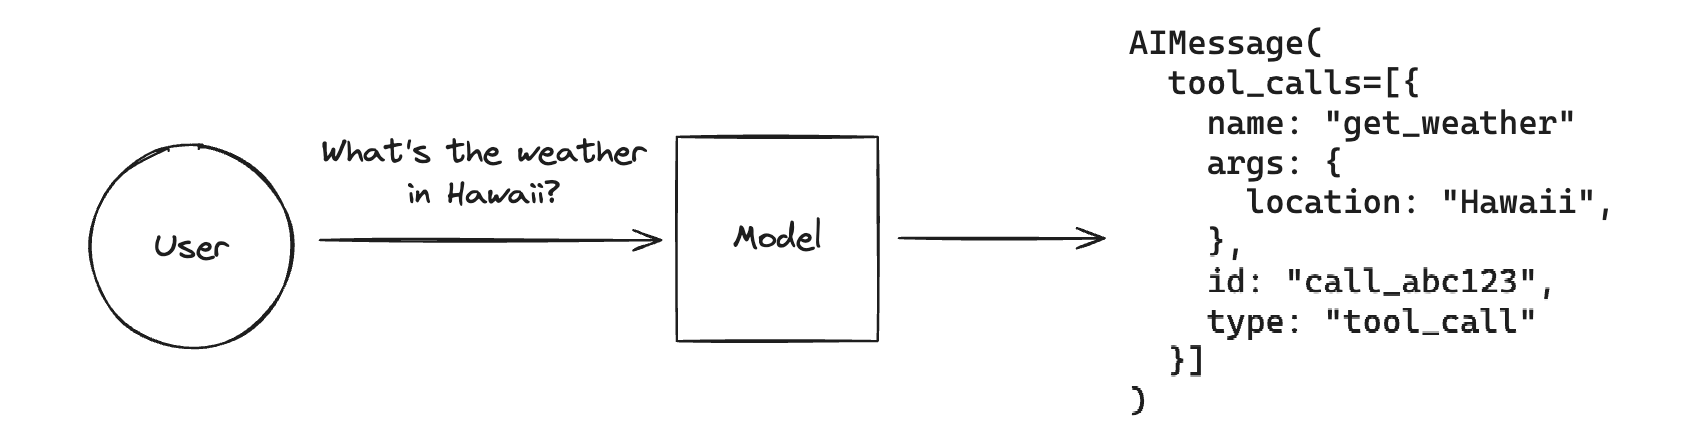

**Definindo esquemas de ferramentas**

>
Para que um modelo possa chamar ferramentas, precisamos fornecer esquemas de ferramentas que descrevam o que a ferramenta faz e quais são seus argumentos. Modelos de *chat* que suportam recursos de chamada de ferramentas implementam um método `.bind_tools()` para passar esquemas de ferramentas para o modelo. Os esquemas de ferramentas podem ser passados como funções Python (com anotações de tipo e docstrings), modelos `Pydantic`, classes `TypedDict` ou objetos LangChain Tool. Chamadas subsequentes ao modelo passarão esses esquemas de ferramentas junto com o *prompt*.


**Funções Python**

Nossos esquemas de ferramentas podem ser funções Python:

In [ ]:
# O nome da função, as anotações de tipo e a docstring compõem
# o esquema que será apresentado ao modelo.
def adicionar(a: int, b: int) -> int:
    """Soma dois números inteiros.

    Args:
        a: Primeiro número inteiro.
        b: Segundo número inteiro.
    """
    return a + b

def multiplicar(a: int, b: int) -> int:
    """Multiplica dois números inteiros.

    Args:
        a: Primeiro número inteiro.
        b: Segundo número inteiro.
    """
    return a * b

O **LangChain** também implementa um decorador `@tool` que permite um controle mais detalhado sobre o esquema da ferramenta, como nomes de ferramentas e descrições de argumentos.

**Classe `Pydantic`**

Você pode definir os esquemas de forma equivalente sem as funções acompanhantes usando Pydantic:

In [ ]:
from pydantic import BaseModel, Field

class adicionar(BaseModel):
    """Esquema de entrada para a operação de soma."""

    a: int = Field(description="Primeiro número inteiro")
    b: int = Field(description="Segundo número inteiro")

class multiplicar(BaseModel):
    """Esquema de entrada para a operação de multiplicação."""

    a: int = Field(description="Primeiro número inteiro")
    b: int = Field(description="Segundo número inteiro")

Ou usando `TypedDicts` e anotações:

In [ ]:
from typing_extensions import Annotated, TypedDict

class adicionar(TypedDict):
    """Esquema de entrada para a operação de soma."""

    a: Annotated[int, ..., "Primeiro número inteiro"]
    b: Annotated[int, ..., "Segundo número inteiro"]

class multiplicar(TypedDict):
    """Esquema de entrada para a operação de multiplicação."""

    a: Annotated[int, ..., "Primeiro número inteiro"]
    b: Annotated[int, ..., "Segundo número inteiro"]

In [ ]:
tools = [adicionar, multiplicar]

Para realmente vincular esses esquemas a um modelo de *chat*, usaremos o método `.bind_tools()`. Isso trata de converter os esquemas de `adicionar` e `multiplicar` para o formato adequado para o modelo. O esquema da ferramenta será passado a cada vez que o modelo for invocado.

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(model="gpt-6-luna", api_key=OPENAI_API_KEY)

In [ ]:
modelo_tools = modelo.bind_tools(tools)

consulta = "Quanto é 3 * 12?"

modelo_tools.invoke(consulta)

AIMessage(content=[{'arguments': '{"a":3,"b":12}', 'call_id': 'call_rugGphpu0uo2miszaBdcWdUG', 'name': 'multiplicar', 'type': 'function_call', 'id': 'fc_08bc349e4d886f76006afaf747691887d1b66ed3dd1ed51ff0', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_08bc349e4d886f76006afaf7469efc87d1b09f595ba0d46115', 'created_at': 1794832198.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='resp_08bc349e4d886f76006afaf7469efc87d1b09f595ba0d46115', tool_calls=[{'name': 'multiplicar', 'args': {'a': 3, 'b': 12}, 'id': 'call_rugGphpu0uo2miszaBdcWdUG', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 106, 'output_tokens': 23, 'total_tokens': 129, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}, 'output_token_details': {'reasoning': 0}})

**Chamadas de ferramenta**

Se chamadas de ferramentas estiverem incluídas em uma resposta de LLM, elas são anexadas à mensagem ou ao trecho da mensagem correspondente como uma lista de objetos de chamada de ferramenta no atributo `.tool_calls`.

Observe que modelos de *chat* podem chamar várias ferramentas ao mesmo tempo.

Um `ToolCall` é um dicionário tipado que inclui um nome de ferramenta, um dicionário de valores de argumentos e (opcionalmente) um identificador. Mensagens sem chamadas de ferramenta têm uma lista vazia por padrão para este atributo.

In [ ]:
consulta = "Qual é o resultado de 3 * 12? E qual é o resultado de 11 + 49?"

modelo_tools.invoke(consulta).tool_calls

[{'name': 'multiplicar',
  'args': {'a': 3, 'b': 12},
  'id': 'call_Ra6YWjyMzvObXi1REyPCitaC',
  'type': 'tool_call'},
 {'name': 'adicionar',
  'args': {'a': 11, 'b': 49},
  'id': 'call_x3MsrgCm9w5nLRfMaJ2TibMn',
  'type': 'tool_call'}]

***Parsing***
>
Se desejado, *parsers* de saída podem processar ainda mais a saída. Por exemplo, podemos converter valores existentes preenchidos no `.tool_calls` em objetos `Pydantic` usando o `PydanticToolsParser`:

In [ ]:
from langchain_core.output_parsers import PydanticToolsParser
from pydantic import BaseModel, Field

class adicionar(BaseModel):
    """Esquema de entrada para a operação de soma."""
    a: int = Field(description="Primeiro número inteiro")
    b: int = Field(description="Segundo número inteiro")

class multiplicar(BaseModel):
    """Esquema de entrada para a operação de multiplicação."""
    a: int = Field(description="Primeiro número inteiro")
    b: int = Field(description="Segundo número inteiro")

In [ ]:
chain = modelo_tools | PydanticToolsParser(tools=[adicionar, multiplicar])
chain.invoke(consulta)

[multiplicar(a=3, b=12), adicionar(a=11, b=49)]

**Como passar saídas de ferramentas para modelos de *chat***


Alguns modelos são capazes de realizar chamadas de ferramentas - gerando argumentos que se conformam a um esquema específico fornecido pelo usuário.


Agora vamos demonstrar como usar essas chamadas de ferramentas para realmente chamar uma função e passar os resultados corretamente de volta para o modelo.

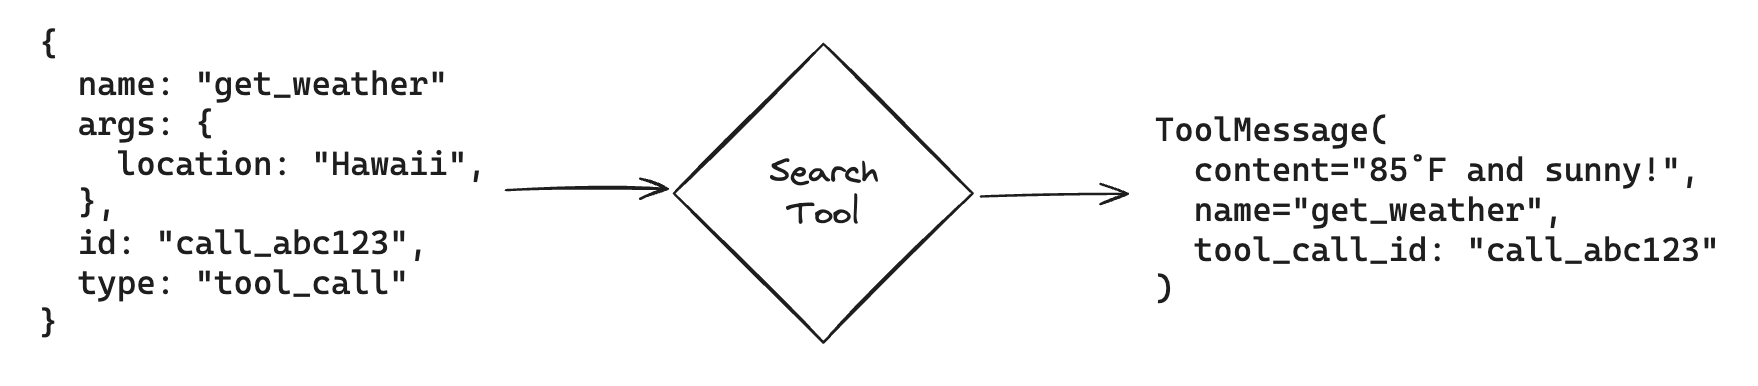

Primeiro, vamos definir o modelo e as nossas ferramentas:

In [ ]:
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(model="gpt-6-luna", api_key=OPENAI_API_KEY)

In [ ]:
from langchain.tools import tool

@tool
def adicionar(a: int, b: int) -> int:
    """Soma dois números inteiros."""
    return a + b

@tool
def multiplicar(a: int, b: int) -> int:
    """Multiplica dois números inteiros."""
    return a * b

ferramentas = [adicionar, multiplicar]
modelo_tools = modelo.bind_tools(ferramentas)

Agora, vamos fazer com que o modelo chame uma ferramenta. Vamos adicioná-la a uma lista de mensagens que trataremos como histórico de conversa:

In [ ]:
from langchain_core.messages import HumanMessage

consulta = "Quanto é 3 * 12? Além disso, quanto é 11 + 49?"

mensagens = [HumanMessage(consulta)]

ai_msg = modelo_tools.invoke(mensagens)

print(ai_msg.tool_calls)

mensagens.append(ai_msg)

[{'name': 'multiplicar', 'args': {'a': 3, 'b': 12}, 'id': 'call_mnIBavySNq1FmyKXzYU0aEJ1', 'type': 'tool_call'}, {'name': 'adicionar', 'args': {'a': 11, 'b': 49}, 'id': 'call_95KcdK5RlFaP5AOwvLnOoLjU', 'type': 'tool_call'}]


In [ ]:
mensagens

[HumanMessage(content='Quanto é 3 * 12? Além disso, quanto é 11 + 49?', additional_kwargs={}, response_metadata={}),
 AIMessage(content=[{'arguments': '{"a":3,"b":12}', 'call_id': 'call_mnIBavySNq1FmyKXzYU0aEJ1', 'name': 'multiplicar', 'type': 'function_call', 'id': 'fc_08d2013c59d749e2006afaf7dd22a487d1a40c1419e4d4be5b', 'status': 'completed'}, {'arguments': '{"a":11,"b":49}', 'call_id': 'call_95KcdK5RlFaP5AOwvLnOoLjU', 'name': 'adicionar', 'type': 'function_call', 'id': 'fc_08d2013c59d749e2006afaf7dd22b487d1ae3347bf073d3426', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_08d2013c59d749e2006afaf7dbb33487d18c4fa7cd6bc66a41', 'created_at': 1794832347.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='resp_08d2013c59d749e2006afaf7dbb33487d18c4fa7cd6bc66a41', tool_calls=[{'name': 'multiplicar', 'args': {'a': 3, 'b': 12}, 'id': 'call_mn

Em seguida, vamos invocar as funções das ferramentas usando os argumentos que o modelo preencheu!

Convenientemente, se invocarmos uma Ferramenta do LangChain com um `ToolCall`, receberemos automaticamente uma `ToolMessage` que pode ser passada de volta para o modelo:

In [ ]:
# O modelo pode solicitar uma ou mais ferramentas.
ferramentas_por_nome = {
    "adicionar": adicionar,
    "multiplicar": multiplicar,
}

for chamada in ai_msg.tool_calls:
    ferramenta_selecionada = ferramentas_por_nome[chamada["name"]]
    mensagem_ferramenta = ferramenta_selecionada.invoke(chamada)
    mensagens.append(mensagem_ferramenta)

mensagens

[HumanMessage(content='Quanto é 3 * 12? Além disso, quanto é 11 + 49?', additional_kwargs={}, response_metadata={}),
 AIMessage(content=[{'arguments': '{"a":3,"b":12}', 'call_id': 'call_mnIBavySNq1FmyKXzYU0aEJ1', 'name': 'multiplicar', 'type': 'function_call', 'id': 'fc_08d2013c59d749e2006afaf7dd22a487d1a40c1419e4d4be5b', 'status': 'completed'}, {'arguments': '{"a":11,"b":49}', 'call_id': 'call_95KcdK5RlFaP5AOwvLnOoLjU', 'name': 'adicionar', 'type': 'function_call', 'id': 'fc_08d2013c59d749e2006afaf7dd22b487d1ae3347bf073d3426', 'status': 'completed'}], additional_kwargs={}, response_metadata={'id': 'resp_08d2013c59d749e2006afaf7dbb33487d18c4fa7cd6bc66a41', 'created_at': 1794832347.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='resp_08d2013c59d749e2006afaf7dbb33487d18c4fa7cd6bc66a41', tool_calls=[{'name': 'multiplicar', 'args': {'a': 3, 'b': 12}, 'id': 'call_mn

E, finalmente, vamos invocar o modelo com os resultados das ferramentas. O modelo usará essas informações para gerar uma resposta final à nossa consulta original:

In [ ]:
resposta = modelo_tools.invoke(mensagens)

In [ ]:
resposta

AIMessage(content=[{'type': 'text', 'text': '3 × 12 = 36.  \n11 + 49 = 60.', 'annotations': [], 'id': 'msg_08d2013c59d749e2006afaf817341487d1b75b5f7594746a24', 'phase': 'final_answer'}], additional_kwargs={}, response_metadata={'id': 'resp_08d2013c59d749e2006afaf816962087d1b43ad21c2f7eb6e4', 'created_at': 1794832406.0, 'metadata': {}, 'model': 'gpt-6-luna', 'object': 'response', 'service_tier': 'default', 'status': 'completed', 'model_provider': 'openai', 'model_name': 'gpt-6-luna'}, id='resp_08d2013c59d749e2006afaf816962087d1b43ad21c2f7eb6e4', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 169, 'output_tokens': 21, 'total_tokens': 190, 'input_token_details': {'cache_creation': 0, 'cache_read': 0}, 'output_token_details': {'reasoning': 0}})

In [ ]:
resposta.content

[{'type': 'text',
  'text': '3 × 12 = 36.  \n11 + 49 = 60.',
  'annotations': [],
  'id': 'msg_08d2013c59d749e2006afaf817341487d1b75b5f7594746a24',
  'phase': 'final_answer'}]

In [ ]:
from IPython.core.display import Markdown

Markdown(resposta.text)

3 × 12 = 36.  
11 + 49 = 60.

Observe que cada `ToolMessage` deve incluir um `tool_call_id` que corresponda a um `id` nas chamadas de ferramentas originais geradas pelo modelo. Isso ajuda o modelo a associar as respostas das ferramentas com as chamadas de ferramentas.

**Como passar dados multimodais diretamente para modelos**

Neste exemplo, vamos pedir a um modelo para descrever uma imagem.

In [ ]:
url = "https://images.unsplash.com/photo-1500530855697-b586d89ba3ee"

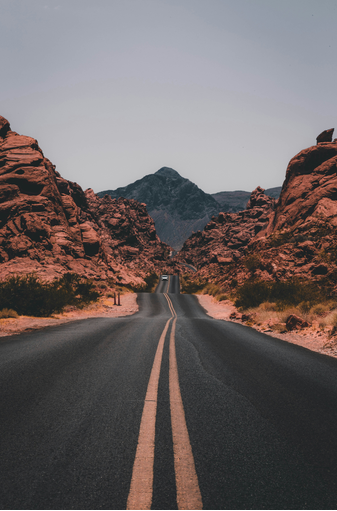

In [ ]:
# Cabeçalho HTTP para identificar a requisição
headers = {
    "User-Agent": "Mozilla/5.0 (compatible; PythonImageExample/1.0)",
    "Referer": "https://commons.wikimedia.org/"
}

In [ ]:
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI

modelo = ChatOpenAI(model="gpt-6-luna", api_key=OPENAI_API_KEY)

Uma imagem pode ser enviada ao modelo como URL ou como dados codificados em `Base64`, desde que o provedor e o modelo ofereçam suporte ao formato utilizado.

In [ ]:
import base64
import httpx

resposta_http = httpx.get(url, headers=headers, timeout=30)

imagem = base64.b64encode(resposta_http.content).decode("utf-8")
url_base64 = f"data:image/jpeg;base64,{imagem}"

Podemos fornecer a URL da imagem diretamente em um bloco de conteúdo do tipo `image_url`. Observe que apenas alguns provedores de modelos oferecem suporte para isso.

In [ ]:
mensagem = HumanMessage(
    content=[
        {"type": "text", "text": "Descreva o ambiente apresentado nesta imagem."},
        {"type": "image_url", "image_url": {"url": url_base64}},
    ],
)

resposta = modelo.invoke([mensagem])

In [ ]:
resposta.content

'A imagem mostra uma estrada asfaltada de duas pistas que atravessa uma paisagem árida, cercada por formações rochosas avermelhadas e vegetação rasteira. Ao fundo há montanhas sob um céu amplo e claro, e um carro branco aparece na estrada. O cenário transmite a sensação de uma viagem por uma região desértica e remota.'

Alguns modelos multimodais também suportam recursos de chamadas de ferramentas. Para chamar ferramentas usando esses modelos, basta vincular as ferramentas a eles da maneira usual e invocar o modelo usando blocos de conteúdo do tipo desejado (por exemplo, contendo dados de imagem).

In [ ]:
url = "https://images.unsplash.com/photo-1519692933481-e162a57d6721?w=1200"

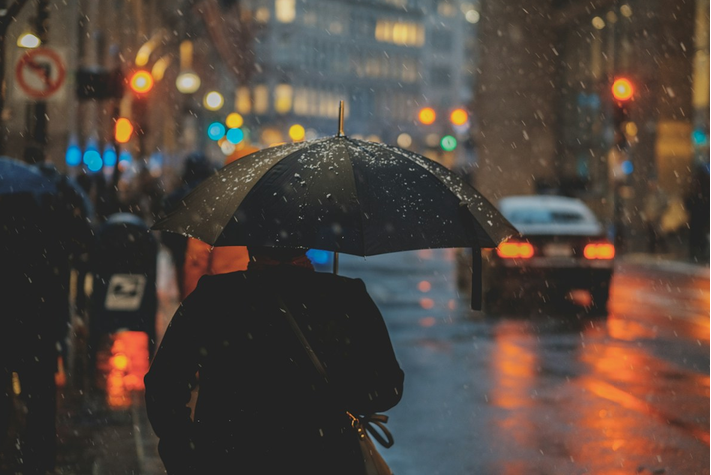

In [ ]:
import base64
import httpx

resposta_http = httpx.get(url, headers=headers, timeout=30)

imagem = base64.b64encode(resposta_http.content).decode("utf-8")
url_base64 = f"data:image/jpeg;base64,{imagem}"

In [ ]:
from typing import Literal
from langchain.tools import tool
from langchain.messages import HumanMessage

@tool
def clima_tool(
    clima: Literal["ensolarado", "nublado", "chuvoso"]
) -> str:
    """Registra a condição climática identificada na imagem."""
    return f"Condição climática identificada: {clima}."

modelo_tools = modelo.bind_tools([clima_tool])

mensagem = HumanMessage(
    content=[
        {"type": "text", "text": "Analise a imagem e selecione a condição climática mais adequada."},
        {"type": "image_url", "image_url": {"url": url_base64}},
    ],
)

In [ ]:
resposta = modelo_tools.invoke([mensagem])
print(resposta.tool_calls)

[{'name': 'clima_tool', 'args': {'clima': 'chuvoso'}, 'id': 'call_HlVQtWfAvDFjNyvsimP0TJD8', 'type': 'tool_call'}]
